# LangChain and LangGraph fundamentals

Get familiar with LangChain's model calls, messages, and prompt templates, then LangGraph's state, nodes, edges, and conditional routing.
Use Arize to inspect the workflow's prompts, responses, and execution times.

Complete the environment setup first. Use the **Python (problem_first_ai)** kernel and keep your credentials in `.env`.

## LangChain: Models, messages, and prompt templates

### Load environment variables

Load the OpenAI and Arize settings from `.env`. Print the first 20 characters of each required value to check that it loaded.

In [1]:
import sys
print(sys.executable)

/usr/local/bin/python3


In [9]:
import os
from dotenv import load_dotenv

load_dotenv()
# print("OPENAI_API_KEY:", os.environ["OPENAI_API_KEY"][:20])
print("OPENROUTER_API_KEY:", os.environ["OPENROUTER_API_KEY"][:20])
print("ARIZE_API_KEY:", os.environ["ARIZE_API_KEY"][:20])
print("ARIZE_SPACE_ID:", os.environ["ARIZE_SPACE_ID"][:20])

### Call a model with messages

Initialize the chat model. A `SystemMessage` provides instructions, and a `HumanMessage` contains the user's input.
`model.invoke()` returns an `AIMessage`; its `.text` property gives us the reply text.

The response below is an Italian translation of the English sentence.

In [11]:
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage, SystemMessage

# model = init_chat_model(
#     "gpt-5-mini",
#     model_provider="openai",
#     reasoning_effort="minimal",
# )

model = init_chat_model(
    "openai/gpt-5-mini",
    model_provider="openrouter",
    max_tokens=4000,                  # Lower max_tokens to fit within your key's credit limit
    reasoning={"effort": "minimal"},  # Correct syntax for OpenRouter reasoning config
)

messages = [
    SystemMessage("Translate the following from English into Italian"),
    HumanMessage("I'm excited to get started with the Problem-First AI course!"),
]

response = model.invoke(messages)
print(response.text)

Sono entusiasta di iniziare il corso Problem-First AI!


### Format a reusable prompt

`ChatPromptTemplate` keeps the message roles and named placeholders together.
Create a fortune-telling prompt with a `{question}` placeholder, then supply the question through `invoke()`.

Inspect the formatted prompt below. The human message contains the question in place of `{question}`.

In [12]:
from langchain_core.prompts import ChatPromptTemplate

fortune_prompt = ChatPromptTemplate([
    (
        "system",
        "You are a wise and mystical AI fortune teller. Your predictions are "
        "funny, slightly exaggerated, but insightful. Keep it to 1-2 sentences",
    ),
    ("human", "Please entertain the user with their fortune request: {question}"),
])

question = "What is the next trillion dollar idea?"
prompt = fortune_prompt.invoke({"question": question})
print(prompt)

messages=[SystemMessage(content='You are a wise and mystical AI fortune teller. Your predictions are funny, slightly exaggerated, but insightful. Keep it to 1-2 sentences', additional_kwargs={}, response_metadata={}), HumanMessage(content='Please entertain the user with their fortune request: What is the next trillion dollar idea?', additional_kwargs={}, response_metadata={})]


### Read the response text

Pass the formatted prompt to the same model. Read `.text` to get the fortune as a string.

In [13]:
fortune = model.invoke(prompt).text
print(fortune)

I see shimmering servers and gardens of data — the next trillion-dollar idea is "personal AI ecosystems": subscription-native AI companions that own and monetize your data for you, negotiating deals with companies while you sleep. Invest in privacy-first identity wallets, tiny sensors, and emotional-ROI analytics — and buy popcorn for the inevitable regulatory fireworks.


In [14]:
fortune = model.invoke(prompt)
print(fortune)

content='Ah — the stars whisper of a trillion-dollar seed: a tidy conjuration of AI, home energy alchemy, and invisible grids — imagine rooftop fusion of solar + smart storage + instant neighborhood energy markets, run by tiny predictive AIs that sell power like stocks; it turns rooftops into micro-banks and makes utilities nervous. Invest in solving seamless hardware reliability and trust (blockchain or better), and you’ll laugh all the way to the electric co-op.' additional_kwargs={'reasoning_details': [{'data': 'gAAAAABq0_Nz1xvhhrBEAncf51FpvGQ-_g48tR_44PdQ0qfpj2NeUk3hSkjmuRfL05SAw1Llax7SLko4TD29Iuf_I4L2hFFzwYLqDixtnQpk06Dr0MOAZ9ZC-B1uzbEH0xKC1g8XDNrs3UFf0QvbmWRoKkqBpZ6pfhhB3lRr50mAn43siO8CGu7VaPSIRqWMAiCz6SU8pwhIsZXbOjxbu_-NkzQ_NEEoMLOrfjne4JaoSi7gXwc_zD26wbetgal1twPmVlZnpjbARcmenwfsLalD43vKNUvuLaXose_b_r8X1Zw_vtjI9nH36KD36a0JlUkR5TjwDExkJotpO5nHNtVrYx6Ncouvyp_yKVPaxo388XvJCRsrzIEXUnd3-865p7Cq2hDx2X4X-N-ZGGD4Gv--LGpJke-7nx3gHbRhk8rmwlLVkuJ2bhauZKXlsfS1nawNkkWV7cExOcaKKyH8tp-BSL83XOA

## LangGraph: State, nodes, and edges

### Why use LangGraph?

LangChain provides the model calls, messages, and prompt templates we used above.
LangGraph defines the execution order and passes state between Python functions called nodes.
A node can use a LangChain model or ordinary Python code.

Edges connect the nodes. Conditional edges choose the next node based on the current state.
Start with a fixed sequence, then use a model's response to choose a branch.

### Build a graph with Python functions

#### Start with plain Python

Generate ten random integers and add them. Print the numbers and their total before putting these operations into a graph.

In [15]:
import random

values = [random.randint(0, 10) for _ in range(10)]
print("Generated values:", values)
print("Total:", sum(values))

Generated values: [8, 6, 1, 8, 0, 5, 1, 6, 1, 10]
Total: 46


#### Define the state

State holds the data passed between nodes. `TypedDict` describes the fields and their types.
Start this graph with `num_values`; the nodes add `generated_values` and `total` as they run.

In [16]:
from typing import TypedDict
from langgraph.graph import START, END, StateGraph

class NumberState(TypedDict):
    num_values: int
    generated_values: list[int]
    total: int

#### Return state updates from each node

Each node reads the state and returns a dictionary containing the fields it changes.
`generate_values` returns the new list. `add_values` reads that list and returns its total.
LangGraph keeps the other fields in the state.

In [17]:
def generate_values(state: NumberState) -> dict:
    values = [random.randint(0, 10) for _ in range(state["num_values"])]
    return {"generated_values": values}

def add_values(state: NumberState) -> dict:
    return {"total": sum(state["generated_values"])}

#### Connect and compile the graph

Add the functions as nodes and connect them with edges.
`START` marks the entry point, and `END` marks completion.
`compile()` creates the graph we can run.

In [18]:
number_builder = StateGraph(NumberState)
number_builder.add_node("generate_values", generate_values)
number_builder.add_node("add_values", add_values)

number_builder.add_edge(START, "generate_values")
number_builder.add_edge("generate_values", "add_values")
number_builder.add_edge("add_values", END)

number_graph = number_builder.compile()

#### View and run the graph

The diagram shows `generate_values` followed by `add_values`.
Invoke the graph with the number of values to generate. The result contains all three state fields.

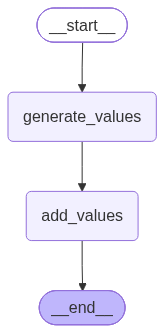

In [19]:
from IPython.display import Image, display

display(Image(number_graph.get_graph().draw_mermaid_png()))

In [20]:
number_result = number_graph.invoke({"num_values": 10})
print(number_result)

{'num_values': 10, 'generated_values': [10, 9, 10, 3, 10, 0, 3, 10, 0, 3], 'total': 58}


#### Follow the state updates

Run the graph with `stream_mode="values"` to see the full state before execution and after each node.
The three dictionaries show how state accumulates:

- Initially, the state contains only `num_values`.
- After `generate_values`, it also contains `generated_values`.
- After `add_values`, it contains `total` as well. The previous fields remain.

Each run generates a new list of random numbers.

In [21]:
number_states = list(number_graph.stream({"num_values": 10}, stream_mode="values"))
for state in number_states:
    print(state)

{'num_values': 10}
{'num_values': 10, 'generated_values': [10, 3, 3, 0, 8, 8, 0, 8, 4, 6]}
{'num_values': 10, 'generated_values': [10, 3, 3, 0, 8, 8, 0, 8, 4, 6], 'total': 50}


#### Invoke asynchronously

A compiled graph supports both `invoke()` and `ainvoke()`.
Use `await graph.ainvoke(...)` in async code so the caller can yield while waiting for the result.
Both methods return the final state. Jupyter supports `await` directly in a cell.

In [22]:
async_number_result = await number_graph.ainvoke({"num_values": 10})
print(async_number_result)

{'num_values': 10, 'generated_values': [5, 1, 7, 8, 5, 5, 7, 9, 4, 4], 'total': 55}


### Enable Arize tracing

Register the Arize project and instrument the model calls before running the graph.
The credentials come from the `.env` file loaded at the start of the notebook.

In [26]:
from arize.otel import register
from openinference.instrumentation.langchain import LangChainInstrumentor

tracer_provider = register(
    space_id=os.environ["ARIZE_SPACE_ID"],
    api_key=os.environ["ARIZE_API_KEY"],
    project_name="langGraph-demo",
)

LangChainInstrumentor().instrument(tracer_provider=tracer_provider)

🔭 OpenTelemetry Tracing Details 🔭
|  Arize Project: langGraph-demo
|  Span Processor: BatchSpanProcessor
|  Collector Endpoint: otlp.arize.com
|  Transport: gRPC
|  Transport Headers: {'sdk-language': '****', 'language-version': '****', 'sdk-version': '****', 'sdk-package-name': '****', 'authorization': '****', 'api_key': '****', 'arize-space-id': '****', 'space_id': '****', 'arize-interface': '****'}
|  
|  
|  `register` has set this TracerProvider as the global OpenTelemetry default.
|  To disable this behavior, call `register` with `set_global_tracer_provider=False`.



### Use model calls in graph nodes

Connect two model calls: generate a fortune, then write a joke about it.
Reuse the model and fortune prompt from the LangChain section.

#### Define the state and nodes

Start with `question`. The first node returns `fortune`, and the second returns `joke`.
Each update preserves the fields already in the state, just as in the number graph.

In [27]:
class JokeState(TypedDict):
    question: str
    fortune: str
    joke: str

joke_prompt = ChatPromptTemplate([
    (
        "system",
        "You are a stand-up comedian who tells hilarious jokes in a casual, "
        "witty style using AI terminology. Keep it short",
    ),
    ("human", "Tell a joke about this fortune telling: {fortune}."),
])

def generate_fortune(state: JokeState) -> dict:
    prompt = fortune_prompt.invoke({"question": state["question"]})
    return {"fortune": model.invoke(prompt).text}

def generate_joke(state: JokeState) -> dict:
    prompt = joke_prompt.invoke({"fortune": state["fortune"]})
    return {"joke": model.invoke(prompt).text}

#### Connect and compile the graph

Register the two functions as nodes. Connect `START` to `generate_fortune`, then `generate_joke`, and finally `END`.
Compile the graph to create the workflow we can invoke.

In [28]:
builder = StateGraph(JokeState)
builder.add_node("generate_fortune", generate_fortune)
builder.add_node("generate_joke", generate_joke)

builder.add_edge(START, "generate_fortune")
builder.add_edge("generate_fortune", "generate_joke")
builder.add_edge("generate_joke", END)

graph = builder.compile()

#### View the workflow

The diagram shows both nodes in order, with a start and an end.

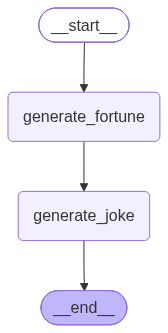

In [29]:
display(Image(graph.get_graph().draw_mermaid_png()))

#### Run the workflow

Supply the question as the initial state. The first node adds the fortune, and the second uses that fortune to produce the joke.
The result contains the question and both generated responses.

In [30]:
result = graph.invoke({"question": question})

print("Question:", result["question"])
print("Fortune:", result["fortune"])
print("Joke:", result["joke"])

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/openinference/instrumentation/_spans.py:64: LangChainDeprecationWarning: Calling .text() as a method is deprecated. Use .text as a property instead (e.g., message.text).
  masked_value = self._self_config.mask(key, value)


Question: What is the next trillion dollar idea?
Fortune: I see a neon-lit vision of a trillion-dollar idea: a decentralized wellness platform that blends personalized biotech diagnostics, AI-curated microdosing regimens, and immersive VR healing retreats—sold as a subscription for stressed-out elites craving optimized longevity. Invest early in empathy, data privacy, and psychedelic-friendly regulations, or the regulators (and your conscience) will turn it into a pumpkin.
Joke: I ran that fortune-telling startup pitch through my ethical compiler — it flagged three issues: a privacy leak, a dependency loop, and excessive sparkle. Output suggestion: pivot to “Decentralized Wellness-as-a-Service” — subscription includes empathy tokens, GDPR plugins, and a complimentary conscience patch. Warning: regulators may auto-update you to PumpkinOS at next patch.


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/openinference/instrumentation/_spans.py:64: LangChainDeprecationWarning: Calling .text() as a method is deprecated. Use .text as a property instead (e.g., message.text).
  masked_value = self._self_config.mask(key, value)


### Choose the next node with conditional edges

Classify a sentence as `happy` or `sad`, then run the matching response node.
A conditional edge selects one branch based on the sentiment stored in state.

#### Define the state and prompts

Start with `sentence`. The classifier adds `sentiment`, and the selected response node adds `message`.
Keep the prompts separate so each node has one task.

In [31]:
class SentimentState(TypedDict):
    sentence: str
    sentiment: str
    message: str

sentiment_prompt = ChatPromptTemplate([
    ("system", "Analyze sentiment. Reply with ONLY 'happy' or 'sad'."),
    ("human", "{sentence}"),
])

happy_prompt = ChatPromptTemplate([
    ("system", "Generate a cheerful, uplifting message in 1 sentence."),
    ("human", "The person said: {sentence}"),
])

sad_prompt = ChatPromptTemplate([
    ("system", "Generate a comforting message in 1 sentence that says it's alright."),
    ("human", "The person said: {sentence}"),
])

#### Define the model nodes

Each node formats its prompt, invokes the model, and reads `.text`.
The classifier strips whitespace and lowercases its reply to produce the route label.

In [32]:
def analyze_sentiment(state: SentimentState) -> dict:
    prompt = sentiment_prompt.invoke({"sentence": state["sentence"]})
    sentiment = model.invoke(prompt).text.strip().lower()
    return {"sentiment": sentiment}

def happy_response(state: SentimentState) -> dict:
    prompt = happy_prompt.invoke({"sentence": state["sentence"]})
    return {"message": model.invoke(prompt).text}

def sad_response(state: SentimentState) -> dict:
    prompt = sad_prompt.invoke({"sentence": state["sentence"]})
    return {"message": model.invoke(prompt).text}

#### Route to the matching response

The routing function returns the sentiment label from state.
`add_conditional_edges()` maps that label to a node name: `happy` runs `happy_response`, and `sad` runs `sad_response`.
Only the selected response node executes, then the graph reaches `END`.

In [33]:
def route_sentiment(state: SentimentState) -> str:
    return state["sentiment"]

sentiment_builder = StateGraph(SentimentState)
sentiment_builder.add_node("analyze_sentiment", analyze_sentiment)
sentiment_builder.add_node("happy_response", happy_response)
sentiment_builder.add_node("sad_response", sad_response)

sentiment_builder.add_edge(START, "analyze_sentiment")
sentiment_builder.add_conditional_edges(
    "analyze_sentiment",
    route_sentiment,
    {"happy": "happy_response", "sad": "sad_response"},
)
sentiment_builder.add_edge("happy_response", END)
sentiment_builder.add_edge("sad_response", END)

sentiment_graph = sentiment_builder.compile()

#### View the branches

The diagram shows two possible paths after `analyze_sentiment`.
Each run takes one of them.

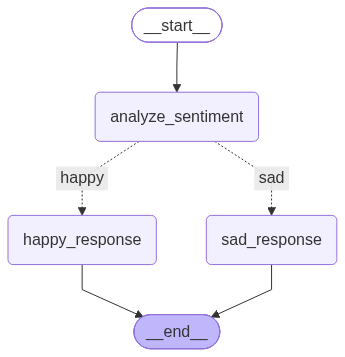

In [34]:
display(Image(sentiment_graph.get_graph().draw_mermaid_png()))

#### Run a happy sentence

The result should contain `sentiment="happy"` and a message from `happy_response`.

In [35]:
happy_result = sentiment_graph.invoke({"sentence": "I got the job! I'm so excited!"})
print("Sentiment:", happy_result["sentiment"])
print("Message:", happy_result["message"])

Sentiment: happy
Message: That's fantastic — congratulations on the new job; you're going to shine and do amazing things!


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/openinference/instrumentation/_spans.py:64: LangChainDeprecationWarning: Calling .text() as a method is deprecated. Use .text as a property instead (e.g., message.text).
  masked_value = self._self_config.mask(key, value)


#### Run a sad sentence

This input should take the other branch, with `sentiment="sad"` and a message from `sad_response`.
The same graph handles both inputs.

In [36]:
sad_result = sentiment_graph.invoke({"sentence": "I failed my exam and feel terrible."})
print("Sentiment:", sad_result["sentiment"])
print("Message:", sad_result["message"])

Sentiment: sad
Message: I'm really sorry—it's okay to feel upset, but remember one exam doesn't define you, you can learn from this and try again when you're ready.


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/openinference/instrumentation/_spans.py:64: LangChainDeprecationWarning: Calling .text() as a method is deprecated. Use .text as a property instead (e.g., message.text).
  masked_value = self._self_config.mask(key, value)


#### Run the model workflow asynchronously

Use `ainvoke()` with the same graph and input format. Await the result, then read the final state.
The conditional edge still chooses the response node from the classifier's output.

In [37]:
async_sentiment_result = await sentiment_graph.ainvoke(
    {"sentence": "I got the job! I'm so excited!"}
)
async_sad_result = await sentiment_graph.ainvoke(
    {"sentence": "I failed my exam and feel terrible."}
)
print("Sentiment:", async_sentiment_result["sentiment"])
print("Message:", async_sentiment_result["message"])
print("--------------------------------")
print("Sentiment:", async_sad_result["sentiment"])
print("Message:", async_sad_result["message"])

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/openinference/instrumentation/_spans.py:64: LangChainDeprecationWarning: Calling .text() as a method is deprecated. Use .text as a property instead (e.g., message.text).
  masked_value = self._self_config.mask(key, value)


Sentiment: happy
Message: That's amazing — congratulations on the new job; your excitement is contagious and I know you’re going to shine and do great things!
--------------------------------
Sentiment: sad
Message: It's alright — one exam doesn't define you, you did your best, and you can learn from this and try again when you're ready.


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/openinference/instrumentation/_spans.py:64: LangChainDeprecationWarning: Calling .text() as a method is deprecated. Use .text as a property instead (e.g., message.text).
  masked_value = self._self_config.mask(key, value)


### Inspect the traces

Flush the completed trace data, then open the `langGraph-demo` project in Arize.
Inspect the fortune-to-joke run to see `generate_fortune` followed by `generate_joke`.
Compare the sentiment runs: each includes `analyze_sentiment` and the selected response node.
Each model call shows its prompt, response, and execution time.

In [ ]:
tracer_provider.force_flush()